# Sales Data Analysis
### Data Analytics Internship - Task 1

## 1. Project Introduction

This notebook performs an end-to-end sales analysis:

1. Load and inspect the sales dataset
2. Clean and validate the data
3. Run exploratory data analysis (EDA)
4. Calculate business KPIs
5. Analyse sales, profit, categories, regions, products and monthly trends
6. Create professional visualisations
7. Derive key findings and business recommendations

**Dataset:** `data/sales_data.csv` - a realistic *sample* sales dataset
(created for this internship task; see the project README for details).

**Currency:** all monetary values are in Indian Rupees (₹).

## 2. Objective

Understand overall sales and profit performance and identify:

- Total sales, total profit, total orders, total quantity and average order value
- Best and worst performing **products**, **categories** and **regions**
- **Sales and profit trends** over time
- Actionable **business insights** and **recommendations**

Every result in this notebook is calculated dynamically from the dataset - no
values are hard-coded.

## 3. Import Libraries

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# --- Locate the project root so this notebook runs from any working directory ---
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "sales_data.csv").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Run the notebook from inside the project folder."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import analysis, data_cleaning, visualization

sns.set_theme(style="whitegrid", font_scale=1.05)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
%matplotlib inline

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\SACHIN.K\OneDrive\Desktop\DA task-1


## 4. Load Dataset

In [2]:
raw_df = data_cleaning.load_dataset()          # data/sales_data.csv
print(f"Dataset loaded: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
raw_df.head()

Dataset loaded: 652 rows x 10 columns


,Order_ID,Order_Date,Customer_Name,Product,Category,Region,Quantity,Sales,Discount,Profit
0,ORD-10640,2025-08-01,Shreya Dutta,Football,Sports,South,2.00,833.40,0.37,-64.72
1,ORD-10266,2025-11-10,Anjali Mishra,Laser Printer,Electronics,West,1.00,"11,397.25",0.13,409.55
2,ORD-10261,2025-09-08,Kavita Saxena,Tablet,Electronics,North,1.00,"22,691.35",0.00,"5,025.58"
3,ORD-10235,2025-04-01,Neha Gupta,Yoga Mat,Sports,West,2.00,915.38,0.12,225.98
4,ORD-10073,2025-10-04,Kavita Saxena,Cricket Bat,Sports,South,1.00,"3,396.74",0.23,67.69


In [3]:
raw_df.tail()

,Order_ID,Order_Date,Customer_Name,Product,Category,Region,Quantity,Sales,Discount,Profit
647,ORD-10072,2025-09-02,Ritika Banerjee,Denim Jeans,Clothing,East,2.00,"3,899.40",0.08,831.28
648,ORD-10107,2025-02-07,Harish Prasad,Winter Jacket,Clothing,South,3.00,"5,175.54",0.37,-114.15
649,ORD-10271,2025-05-02,NaN,Smartphone,Electronics,North,3.00,"36,989.99",0.00,"8,044.06"
650,ORD-10436,2025-11-04,Sonal Pande,Office Chair,Furniture,North,2.00,"10,550.52",0.05,"1,863.94"
651,ORD-10103,2025-06-05,Pooja Deshmukh,Bookshelf,Furniture,North,1.00,"6,326.71",0.00,845.76


## 5. Dataset Overview

In [4]:
overview = pd.DataFrame({
    "Column": raw_df.columns,
    "Data Type": [str(dtype) for dtype in raw_df.dtypes],
    "Non-Null Count": [int(raw_df[col].notna().sum()) for col in raw_df.columns],
    "Missing Values": [int(raw_df[col].isna().sum()) for col in raw_df.columns],
    "Unique Values": [int(raw_df[col].nunique()) for col in raw_df.columns],
})
display(overview)

,Column,Data Type,Non-Null Count,Missing Values,Unique Values
0,Order_ID,str,652,0,640
1,Order_Date,str,649,3,298
2,Customer_Name,str,642,10,46
3,Product,str,650,2,25
4,Category,str,652,0,5
5,Region,str,648,4,6
6,Quantity,float64,649,3,7
7,Sales,float64,649,3,637
8,Discount,float64,644,8,39
9,Profit,float64,649,3,634


In [5]:
print("Duplicate rows :", int(raw_df.duplicated().sum()))
print("Missing cells  :", int(raw_df.isna().sum().sum()))
print("Date column type:", raw_df["Order_Date"].dtype)
print("\nCategory value counts:")
display(raw_df["Category"].value_counts(dropna=False))
print("\nRegion value counts:")
display(raw_df["Region"].value_counts(dropna=False))

Duplicate rows : 12
Missing cells  : 36
Date column type: str

Category value counts:


Category
Grocery        192
Clothing       149
Electronics    133
Sports         114
Furniture       64
Name: count, dtype: int64


Region value counts:


Region
West        185
South       181
North       165
East        113
NaN           4
South         3
North         1
Name: count, dtype: int64

In [6]:
raw_df.describe(include="all")

,Order_ID,Order_Date,Customer_Name,Product,Category,Region,Quantity,Sales,Discount,Profit
count,652,649,642,650,652,648,649.00,649.00,644.00,649.00
unique,640,298,46,25,5,6,NaN,NaN,NaN,NaN
top,ORD-10266,2025-11-27,Neha Gupta,Wireless Headphones,Grocery,West,NaN,NaN,NaN,NaN
freq,2,6,24,50,192,185,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.32,"9,550.32",0.10,"1,418.62"
std,NaN,NaN,NaN,NaN,NaN,NaN,1.45,"18,316.21",0.12,"2,894.20"
min,NaN,NaN,NaN,NaN,NaN,NaN,0.00,"-2,220.66",0.00,"-3,557.09"
25%,NaN,NaN,NaN,NaN,NaN,NaN,1.00,918.22,0.00,26.67
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.00,"3,371.44",0.07,376.17
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.00,"9,650.40",0.16,"1,552.50"


## 6. Data Cleaning

Cleaning steps (performed by `src/data_cleaning.py`):

1. Validate required columns
2. Trim stray whitespace in text fields
3. Convert `Order_Date` to datetime (drop rows with unparseable dates)
4. Coerce numeric columns; drop rows missing **essential** values
   (date, product, category, region, quantity, sales, profit)
5. Fill non-essential missing values (`Customer_Name` -> "Unknown Customer",
   `Discount` -> dataset median)
6. Remove exact duplicate records
7. Remove invalid records (Quantity <= 0, Sales <= 0, Discount outside 0-1)
8. Keep negative profits - they are genuine losses, not errors

In [7]:
print("Quality profile BEFORE cleaning:")
profile_before = data_cleaning.profile_dataset(raw_df)
for key, value in profile_before.items():
    print(f"  {key}: {value}")

Quality profile BEFORE cleaning:
  rows: 652
  columns: 10
  dtypes: {'Order_ID': 'str', 'Order_Date': 'str', 'Customer_Name': 'str', 'Product': 'str', 'Category': 'str', 'Region': 'str', 'Quantity': 'float64', 'Sales': 'float64', 'Discount': 'float64', 'Profit': 'float64'}
  missing_by_column: {'Order_Date': 3, 'Customer_Name': 10, 'Product': 2, 'Region': 4, 'Quantity': 3, 'Sales': 3, 'Discount': 8, 'Profit': 3}
  missing_cells: 36
  duplicate_rows: 12


In [8]:
cleaned_df, cleaning_report = data_cleaning.clean_sales_data(raw_df)
data_cleaning.print_cleaning_summary(cleaning_report)


--- Data cleaning summary -------------------------------------
  Rows      : 652 -> 616  (-36)
  Missing   : 36 -> 0 cells
  Duplicates: 12 -> 0
  Steps applied:
    - Trimmed whitespace in text columns (10 cells adjusted).
    - Converted Order_Date to datetime: 5 row(s) dropped (2 unparseable date string(s), 3 already missing).
    - Coerced numeric columns to number types (17 non-numeric/missing values found).
    - Dropped 15 row(s) missing essential values (Order_Date, Product, Category, Region, Quantity, Sales, Profit).
    - Filled 10 missing Customer_Name value(s) with 'Unknown Customer'.
    - Filled 8 missing Discount value(s) with the median discount (7.00%).
    - Removed 12 exact duplicate record(s).
    - Removed 4 invalid record(s): 2 with Quantity <= 0, 2 with Sales <= 0, 0 with Discount outside [0, 1].
    - 105 order(s) have negative Profit (genuine losses). These are valid business records and were KEPT for analysis.
------------------------------------------------

In [9]:
before, after = cleaning_report["before"], cleaning_report["after"]
comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing cells", "Duplicate rows"],
    "Before Cleaning": [before["rows"], before["columns"], before["missing_cells"], before["duplicate_rows"]],
    "After Cleaning": [after["rows"], after["columns"], after["missing_cells"], after["duplicate_rows"]],
})
display(comparison)

print("Steps applied:")
for step in cleaning_report["steps"]:
    print("  -", step)

,Metric,Before Cleaning,After Cleaning
0,Rows,652,616
1,Columns,10,10
2,Missing cells,36,0
3,Duplicate rows,12,0


Steps applied:
  - Trimmed whitespace in text columns (10 cells adjusted).
  - Converted Order_Date to datetime: 5 row(s) dropped (2 unparseable date string(s), 3 already missing).
  - Coerced numeric columns to number types (17 non-numeric/missing values found).
  - Dropped 15 row(s) missing essential values (Order_Date, Product, Category, Region, Quantity, Sales, Profit).
  - Filled 10 missing Customer_Name value(s) with 'Unknown Customer'.
  - Filled 8 missing Discount value(s) with the median discount (7.00%).
  - Removed 12 exact duplicate record(s).
  - Removed 4 invalid record(s): 2 with Quantity <= 0, 2 with Sales <= 0, 0 with Discount outside [0, 1].


In [10]:
print("Quality profile AFTER cleaning:")
print("  Missing cells :", int(cleaned_df.isna().sum().sum()))
print("  Duplicate rows:", int(cleaned_df.duplicated().sum()))
print("  Order_Date    :", cleaned_df["Order_Date"].dtype)
display(cleaned_df.dtypes)
display(cleaned_df.head())

Quality profile AFTER cleaning:
  Missing cells : 0
  Duplicate rows: 0
  Order_Date    : datetime64[us]


Order_ID                 string
Order_Date       datetime64[us]
Customer_Name            string
Product                  string
Category                 string
Region                   string
Quantity                  int64
Sales                   float64
Discount                float64
Profit                  float64
dtype: object

,Order_ID,Order_Date,Customer_Name,Product,Category,Region,Quantity,Sales,Discount,Profit
0,ORD-10522,2025-01-02,Arjun Menon,Cotton Shirt,Clothing,North,1,"1,561.03",0.00,554.02
1,ORD-10446,2025-01-03,Priyanka Sethi,Tea Pack,Grocery,South,1,242.32,0.14,-1.59
2,ORD-10300,2025-01-03,Ravi Teja,Cooking Oil 1L,Grocery,West,1,138.19,0.09,1.68
3,ORD-10352,2025-01-04,Sonal Pande,Laser Printer,Electronics,West,3,"29,201.31",0.00,"5,781.44"
4,ORD-10560,2025-01-07,Harish Prasad,Sports Shoes,Clothing,North,6,"13,386.11",0.00,"4,629.76"


## 7. Exploratory Data Analysis (EDA)

In [11]:
print("Rows available for analysis:", len(cleaned_df))
print("Date range:", cleaned_df["Order_Date"].min().date(), "->", cleaned_df["Order_Date"].max().date())
display(cleaned_df[["Quantity", "Sales", "Discount", "Profit"]].describe())

Rows available for analysis: 616
Date range: 2025-01-02 -> 2025-12-31


,Quantity,Sales,Discount,Profit
count,616.00,616.00,616.00,616.00
mean,2.33,"9,762.10",0.10,"1,433.94"
std,1.46,"18,669.52",0.11,"2,936.08"
min,1.00,73.62,0.00,"-3,557.09"
25%,1.00,937.73,0.00,25.99
50%,2.00,"3,375.32",0.07,374.82
75%,3.00,"9,814.67",0.16,"1,560.47"
max,6.00,"141,981.64",0.45,"24,229.53"


In [12]:
print("Sales distribution by category:")
display(cleaned_df.groupby("Category")["Sales"].agg(["count", "sum", "mean"]))
print("\nSales distribution by region:")
display(cleaned_df.groupby("Region")["Sales"].agg(["count", "sum", "mean"]))

Sales distribution by category:


,count,sum,mean
Category,,,
Clothing,141,"913,296.00","6,477.28"
Electronics,124,"3,186,565.76","25,698.11"
Furniture,64,"1,287,101.20","20,110.96"
Grocery,181,"113,912.21",629.35
Sports,106,"512,581.09","4,835.67"



Sales distribution by region:


,count,sum,mean
Region,,,
East,111,"1,003,800.92","9,043.25"
North,157,"1,884,068.18","12,000.43"
South,174,"1,564,110.46","8,989.14"
West,174,"1,561,476.70","8,974.00"


,Quantity,Sales,Discount,Profit
Quantity,1.00,0.08,0.02,0.13
Sales,0.08,1.00,-0.09,0.81
Discount,0.02,-0.09,1.00,-0.31
Profit,0.13,0.81,-0.31,1.00


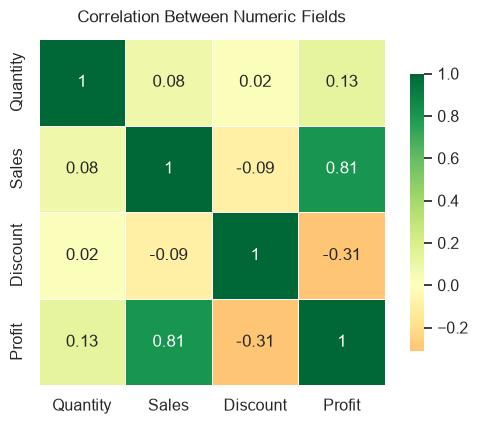

In [13]:
numeric_cols = ["Quantity", "Sales", "Discount", "Profit"]
correlation = cleaned_df[numeric_cols].corr().round(2)
display(correlation)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(correlation, annot=True, cmap="RdYlGn", center=0, ax=ax,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Between Numeric Fields", pad=12)
plt.show()

In [14]:
loss_orders = int((cleaned_df["Profit"] < 0).sum())
print(f"Loss-making orders : {loss_orders} ({loss_orders / len(cleaned_df):.1%} of all orders)")
print(f"Orders with a discount: {int((cleaned_df['Discount'] > 0).sum())}")
print(f"Average discount      : {cleaned_df['Discount'].mean():.2%}")

Loss-making orders : 105 (17.0% of all orders)
Orders with a discount: 370
Average discount      : 9.88%


## 8. KPI Calculation

Headline business KPIs computed from the cleaned dataset.

In [15]:
kpis = analysis.compute_kpis(cleaned_df)
display(analysis.kpi_summary_frame(kpis))

,Metric,Value
0,Total Sales,"6,013,456.26"
1,Total Profit,"883,306.53"
2,Total Orders,616
3,Total Quantity Sold,"1,437"
4,Average Order Value,"9,762.10"
5,Profit Margin (%),14.69
6,Unique Products,25
7,Unique Customers,41
8,Loss-Making Orders,105
9,First Order Date,2025-01-02


## 9. Sales Analysis

In [16]:
print(f"Total Sales: {analysis.format_inr(kpis['Total Sales'])}")
print(f"Average Order Value: {analysis.format_inr(kpis['Average Order Value'])}")
print(f"Total Quantity Sold: {kpis['Total Quantity Sold']:,} units")

Total Sales: ₹6,013,456
Average Order Value: ₹9,762
Total Quantity Sold: 1,437 units


In [17]:
print("Sales by Category")
display(analysis.sales_profit_by(cleaned_df, "Category"))
print("\nSales by Region")
display(analysis.sales_profit_by(cleaned_df, "Region"))

Sales by Category


,Category,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,Electronics,"3,186,565.76","416,357.13",124,205,52.99,47.14,13.07
1,Furniture,"1,287,101.20","132,123.37",64,109,21.40,14.96,10.27
2,Clothing,"913,296.00","241,414.52",141,374,15.19,27.33,26.43
3,Sports,"512,581.09","89,206.71",106,287,8.52,10.10,17.40
4,Grocery,"113,912.21","4,204.80",181,462,1.89,0.48,3.69



Sales by Region


,Region,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,North,"1,884,068.18","265,850.21",157,398,31.33,30.10,14.11
1,South,"1,564,110.46","225,047.88",174,412,26.01,25.48,14.39
2,West,"1,561,476.70","242,515.70",174,390,25.97,27.46,15.53
3,East,"1,003,800.92","149,892.74",111,237,16.69,16.97,14.93


## 10. Profit Analysis

In [18]:
print(f"Total Profit   : {analysis.format_inr(kpis['Total Profit'])}")
print(f"Profit Margin  : {analysis.format_pct(kpis['Profit Margin (%)'])}")
print(f"Loss-making orders: {kpis['Loss-Making Orders']:,} "
      f"({kpis['Loss-Making Orders'] / kpis['Total Orders']:.1%} of orders)")

Total Profit   : ₹883,307
Profit Margin  : 14.7%
Loss-making orders: 105 (17.0% of orders)


In [19]:
print("Profit by Category")
display(analysis.sales_profit_by(cleaned_df, "Category"))
print("\nProfit by Region")
display(analysis.sales_profit_by(cleaned_df, "Region"))

Profit by Category


,Category,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,Electronics,"3,186,565.76","416,357.13",124,205,52.99,47.14,13.07
1,Furniture,"1,287,101.20","132,123.37",64,109,21.40,14.96,10.27
2,Clothing,"913,296.00","241,414.52",141,374,15.19,27.33,26.43
3,Sports,"512,581.09","89,206.71",106,287,8.52,10.10,17.40
4,Grocery,"113,912.21","4,204.80",181,462,1.89,0.48,3.69



Profit by Region


,Region,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,North,"1,884,068.18","265,850.21",157,398,31.33,30.10,14.11
1,South,"1,564,110.46","225,047.88",174,412,26.01,25.48,14.39
2,West,"1,561,476.70","242,515.70",174,390,25.97,27.46,15.53
3,East,"1,003,800.92","149,892.74",111,237,16.69,16.97,14.93


## 11. Category Analysis

In [20]:
category_perf = analysis.sales_profit_by(cleaned_df, "Category")
display(category_perf)

best_sales_cat = category_perf.loc[category_perf["Sales"].idxmax()]
best_profit_cat = category_perf.loc[category_perf["Profit"].idxmax()]
worst_profit_cat = category_perf.loc[category_perf["Profit"].idxmin()]

print(f"Highest sales category : {best_sales_cat['Category']} "
      f"({analysis.format_inr(best_sales_cat['Sales'])})")
print(f"Most profitable category: {best_profit_cat['Category']} "
      f"({analysis.format_inr(best_profit_cat['Profit'])})")
print(f"Lowest profit category  : {worst_profit_cat['Category']} "
      f"({analysis.format_inr(worst_profit_cat['Profit'])})")

,Category,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,Electronics,"3,186,565.76","416,357.13",124,205,52.99,47.14,13.07
1,Furniture,"1,287,101.20","132,123.37",64,109,21.40,14.96,10.27
2,Clothing,"913,296.00","241,414.52",141,374,15.19,27.33,26.43
3,Sports,"512,581.09","89,206.71",106,287,8.52,10.10,17.40
4,Grocery,"113,912.21","4,204.80",181,462,1.89,0.48,3.69


Highest sales category : Electronics (₹3,186,566)
Most profitable category: Electronics (₹416,357)
Lowest profit category  : Grocery (₹4,205)


## 12. Regional Analysis

In [21]:
region_perf = analysis.sales_profit_by(cleaned_df, "Region")
display(region_perf)

best_sales_reg = region_perf.loc[region_perf["Sales"].idxmax()]
best_profit_reg = region_perf.loc[region_perf["Profit"].idxmax()]
worst_profit_reg = region_perf.loc[region_perf["Profit"].idxmin()]

print(f"Highest sales region  : {best_sales_reg['Region']} "
      f"({analysis.format_inr(best_sales_reg['Sales'])})")
print(f"Most profitable region: {best_profit_reg['Region']} "
      f"({analysis.format_inr(best_profit_reg['Profit'])})")
print(f"Weakest region by profit: {worst_profit_reg['Region']} "
      f"({analysis.format_inr(worst_profit_reg['Profit'])})")

,Region,Sales,Profit,Orders,Quantity,Sales Share (%),Profit Share (%),Profit Margin (%)
0,North,"1,884,068.18","265,850.21",157,398,31.33,30.10,14.11
1,South,"1,564,110.46","225,047.88",174,412,26.01,25.48,14.39
2,West,"1,561,476.70","242,515.70",174,390,25.97,27.46,15.53
3,East,"1,003,800.92","149,892.74",111,237,16.69,16.97,14.93


Highest sales region  : North (₹1,884,068)
Most profitable region: North (₹265,850)
Weakest region by profit: East (₹149,893)


## 13. Product Analysis

In [22]:
top_sales = analysis.top_products(cleaned_df, metric="Sales", n=10)
print("Top 10 Products by Sales")
display(top_sales)

Top 10 Products by Sales


,Rank,Product,Sales,Profit,Quantity,Orders
0,1,Laptop,"1,039,592.59","113,188.55",20,12
1,2,Smartphone,"855,037.87","124,052.22",45,28
2,3,Tablet,"852,286.17","135,581.91",42,27
3,4,Sofa Set,"660,833.65","71,939.08",22,11
4,5,Sports Shoes,"318,042.35","81,872.28",93,33
5,6,Cricket Bat,"253,272.25","46,457.43",83,33
6,7,Laser Printer,"232,693.24","23,988.54",24,12
7,8,Wireless Headphones,"206,955.89","19,545.91",74,45
8,9,Steel Almirah,"205,452.38","27,201.35",16,10
9,10,Study Desk,"192,133.59","19,831.58",28,17


In [23]:
top_profit = analysis.top_products(cleaned_df, metric="Profit", n=10)
print("Top 10 Products by Profit")
display(top_profit)

Top 10 Products by Profit


,Rank,Product,Sales,Profit,Quantity,Orders
0,1,Tablet,"852,286.17","135,581.91",42,27
1,2,Smartphone,"855,037.87","124,052.22",45,28
2,3,Laptop,"1,039,592.59","113,188.55",20,12
3,4,Sports Shoes,"318,042.35","81,872.28",93,33
4,5,Sofa Set,"660,833.65","71,939.08",22,11
5,6,Silk Saree,"190,942.93","58,275.41",35,12
6,7,Cricket Bat,"253,272.25","46,457.43",83,33
7,8,Winter Jacket,"165,682.69","42,855.30",74,29
8,9,Cotton Shirt,"131,116.50","31,612.70",109,42
9,10,Steel Almirah,"205,452.38","27,201.35",16,10


In [24]:
worst = analysis.worst_products(cleaned_df, n=5)
print("5 Least Profitable Products")
display(worst)

print(f"Best-selling product      : {top_sales.iloc[0]['Product']} "
      f"({analysis.format_inr(top_sales.iloc[0]['Sales'])})")
print(f"Most profitable product   : {top_profit.iloc[0]['Product']} "
      f"({analysis.format_inr(top_profit.iloc[0]['Profit'])})")
print(f"Lowest-profit product     : {worst.iloc[0]['Product']} "
      f"({analysis.format_inr(worst.iloc[0]['Profit'])})")

5 Least Profitable Products


,Rank,Product,Sales,Profit,Quantity,Orders
0,1,Tea Pack,"17,624.55",271.54,74,30
1,2,Rice Bag 5kg,"43,802.91",605.40,125,42
2,3,Cooking Oil 1L,"14,214.99",784.53,99,44
3,4,Sugar Bag 5kg,"15,025.62",855.97,65,28
4,5,Detergent Powder,"23,244.14","1,687.36",99,37


Best-selling product      : Laptop (₹1,039,593)
Most profitable product   : Tablet (₹135,582)
Lowest-profit product     : Tea Pack (₹272)


## 14. Monthly Trend Analysis

In [25]:
monthly = analysis.monthly_trends(cleaned_df)
display(monthly[["Month_Label", "Sales", "Profit", "Orders", "Quantity", "Profit Margin (%)"]])

peak = monthly.loc[monthly["Sales"].idxmax()]
low = monthly.loc[monthly["Sales"].idxmin()]
print(f"Highest sales month: {peak['Month_Label']} ({analysis.format_inr(peak['Sales'])})")
print(f"Lowest sales month : {low['Month_Label']} ({analysis.format_inr(low['Sales'])})")

,Month_Label,Sales,Profit,Orders,Quantity,Profit Margin (%)
0,Jan 2025,"240,965.99","47,350.79",36,86,19.65
1,Feb 2025,"325,411.17","46,374.20",32,61,14.25
2,Mar 2025,"396,457.98","62,071.61",38,98,15.66
3,Apr 2025,"413,567.49","68,723.15",49,100,16.62
4,May 2025,"674,778.71","89,884.30",51,123,13.32
5,Jun 2025,"203,530.28","19,122.78",40,78,9.40
6,Jul 2025,"474,629.46","59,034.36",55,131,12.44
7,Aug 2025,"584,881.19","83,992.43",49,117,14.36
8,Sep 2025,"510,815.31","78,435.99",50,115,15.36
9,Oct 2025,"921,411.70","135,029.93",70,176,14.65


Highest sales month: Oct 2025 (₹921,412)
Lowest sales month : Jun 2025 (₹203,530)


## 15. Data Visualisations

Seven required charts (plus profit by region) are generated with
Matplotlib/Seaborn and saved to `outputs/charts/`.

In [26]:
chart_paths = visualization.create_all_charts(
    category_perf, region_perf, top_sales, top_profit, monthly,
    output_dir=PROJECT_ROOT / "outputs" / "charts",
)
print(f"Generated {len(chart_paths)} charts:")
for path in chart_paths:
    print("  -", path.relative_to(PROJECT_ROOT))

Generated 8 charts:
  - outputs\charts\01_sales_by_category.png
  - outputs\charts\02_profit_by_category.png
  - outputs\charts\03_sales_by_region.png
  - outputs\charts\04_profit_by_region.png
  - outputs\charts\05_top10_products_by_sales.png
  - outputs\charts\06_top10_products_by_profit.png
  - outputs\charts\07_monthly_sales_trend.png
  - outputs\charts\08_monthly_profit_trend.png


01_sales_by_category.png


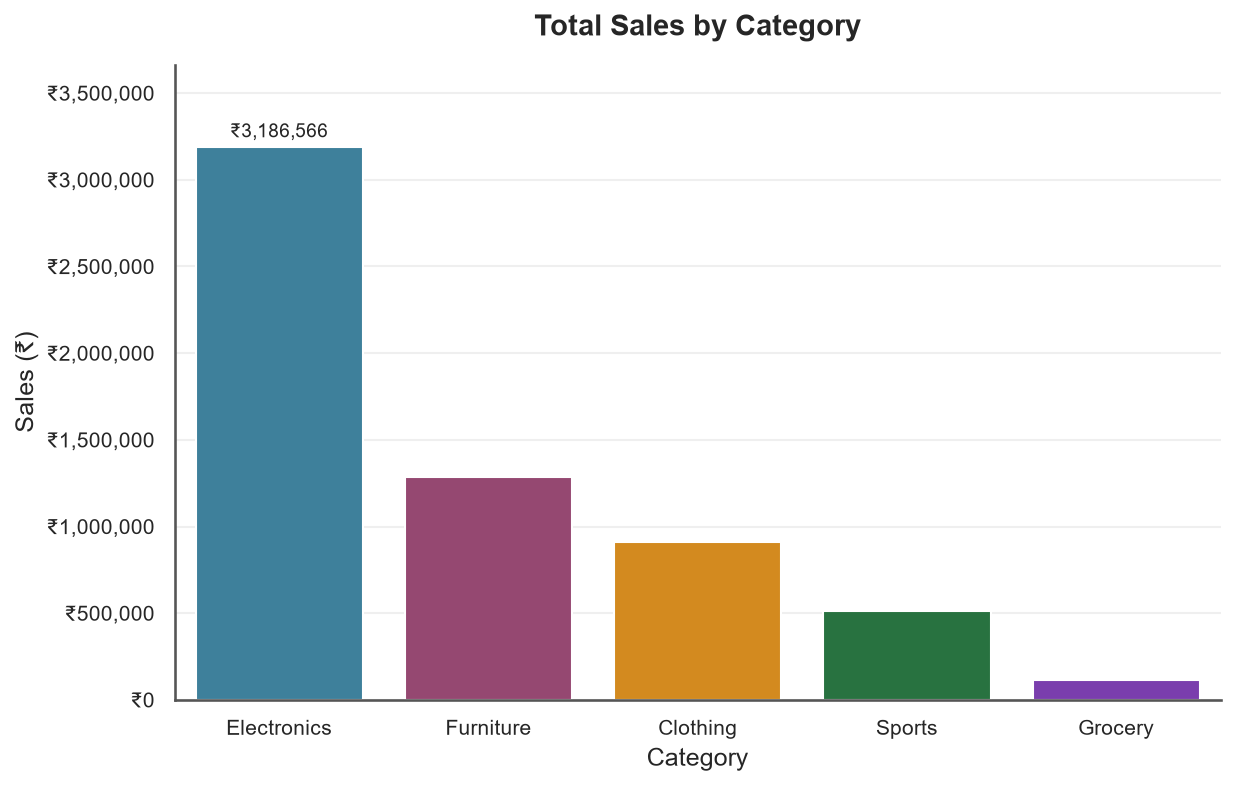

02_profit_by_category.png


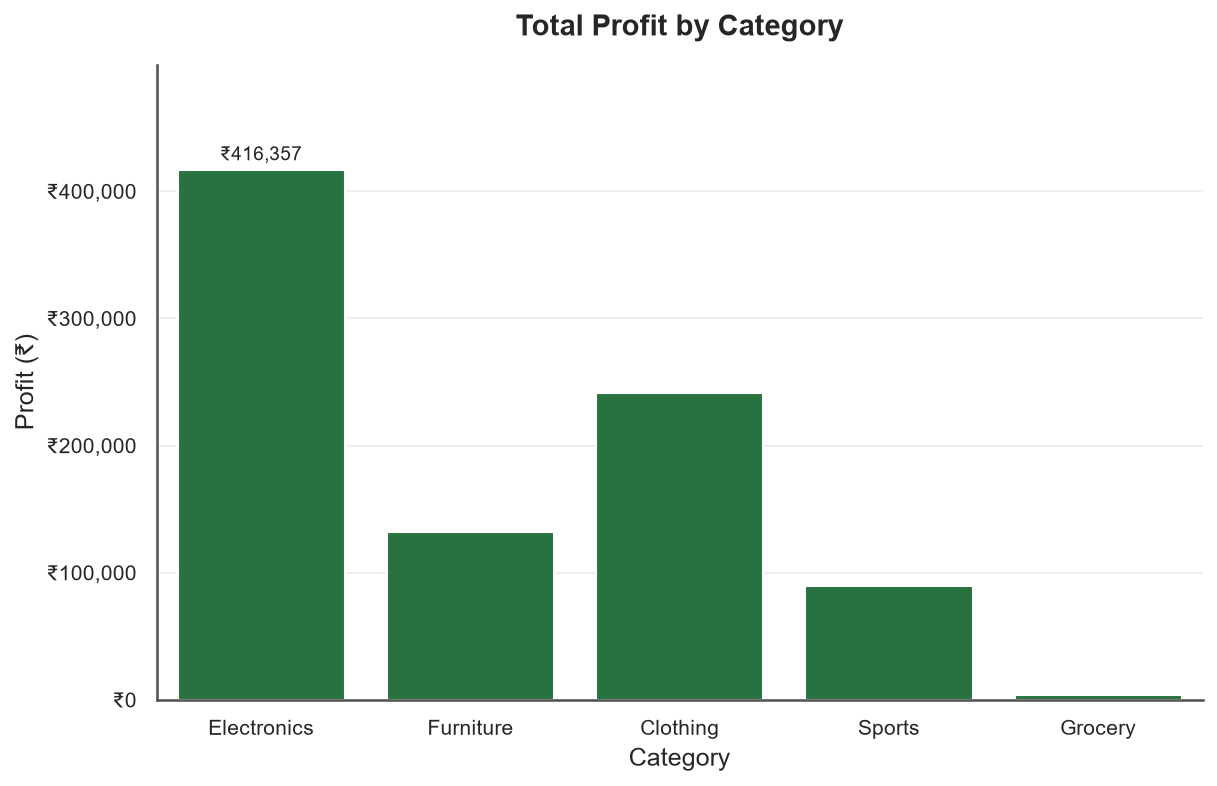

03_sales_by_region.png


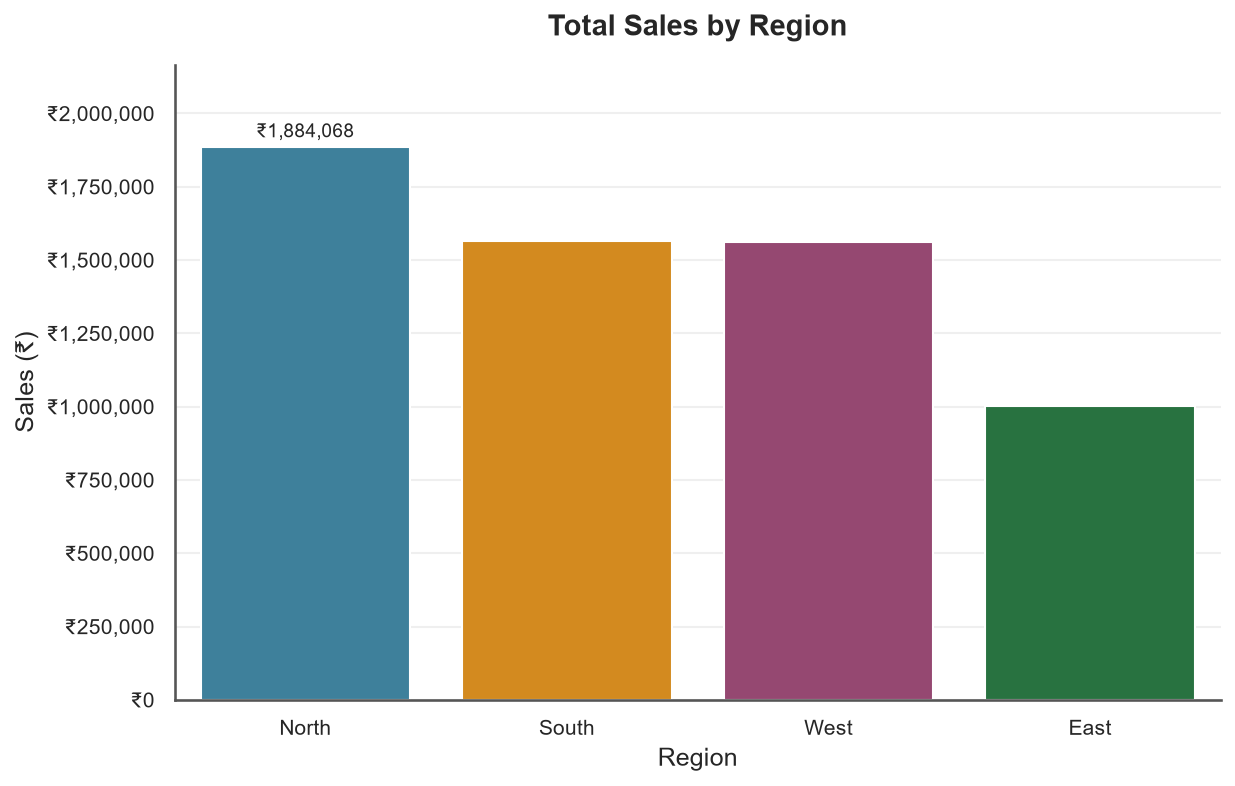

04_profit_by_region.png


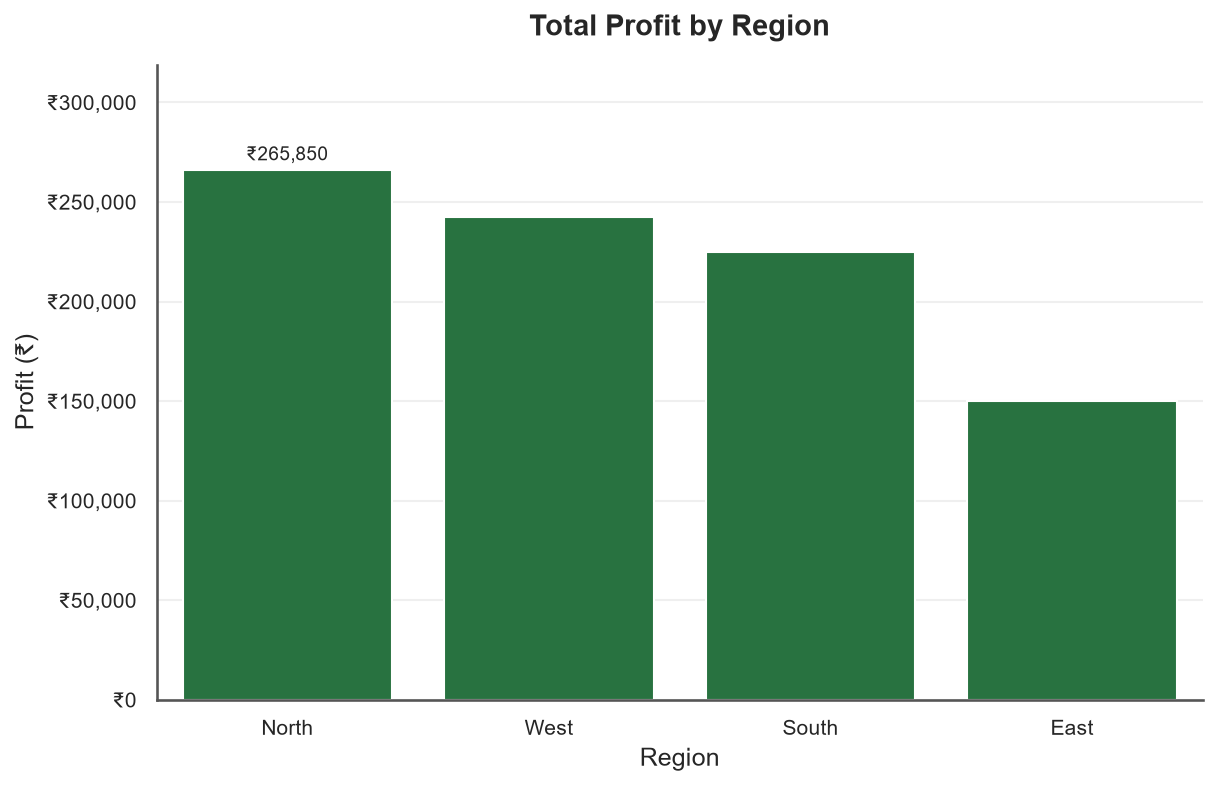

05_top10_products_by_sales.png


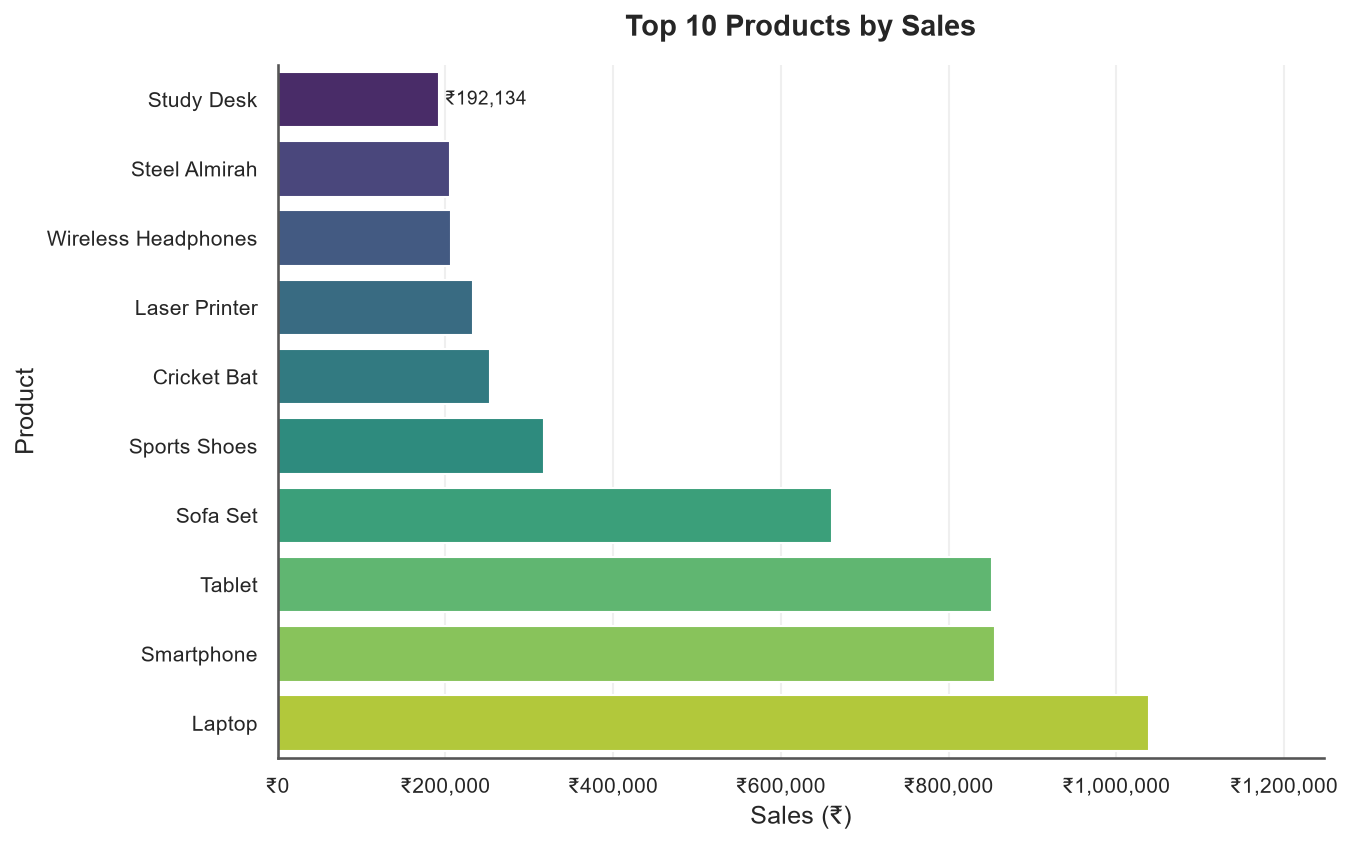

06_top10_products_by_profit.png


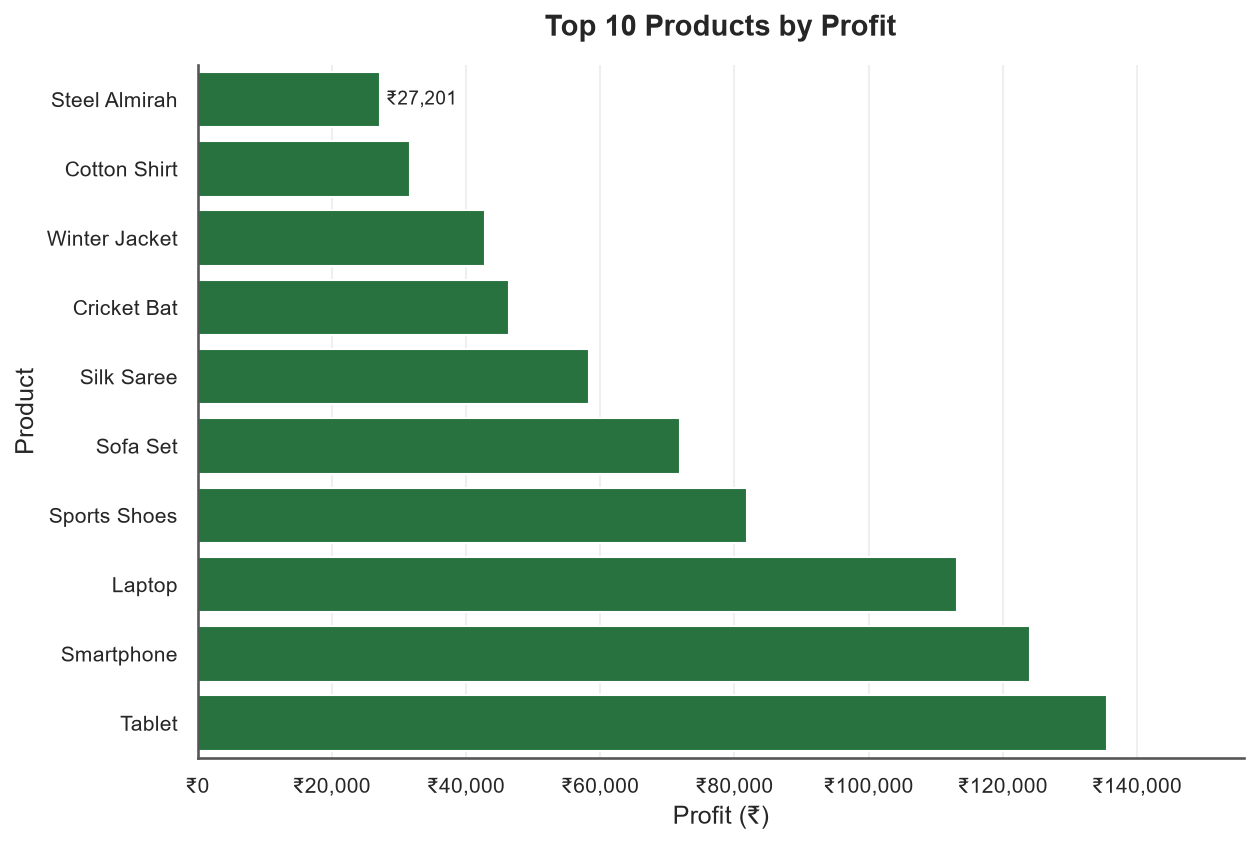

07_monthly_sales_trend.png


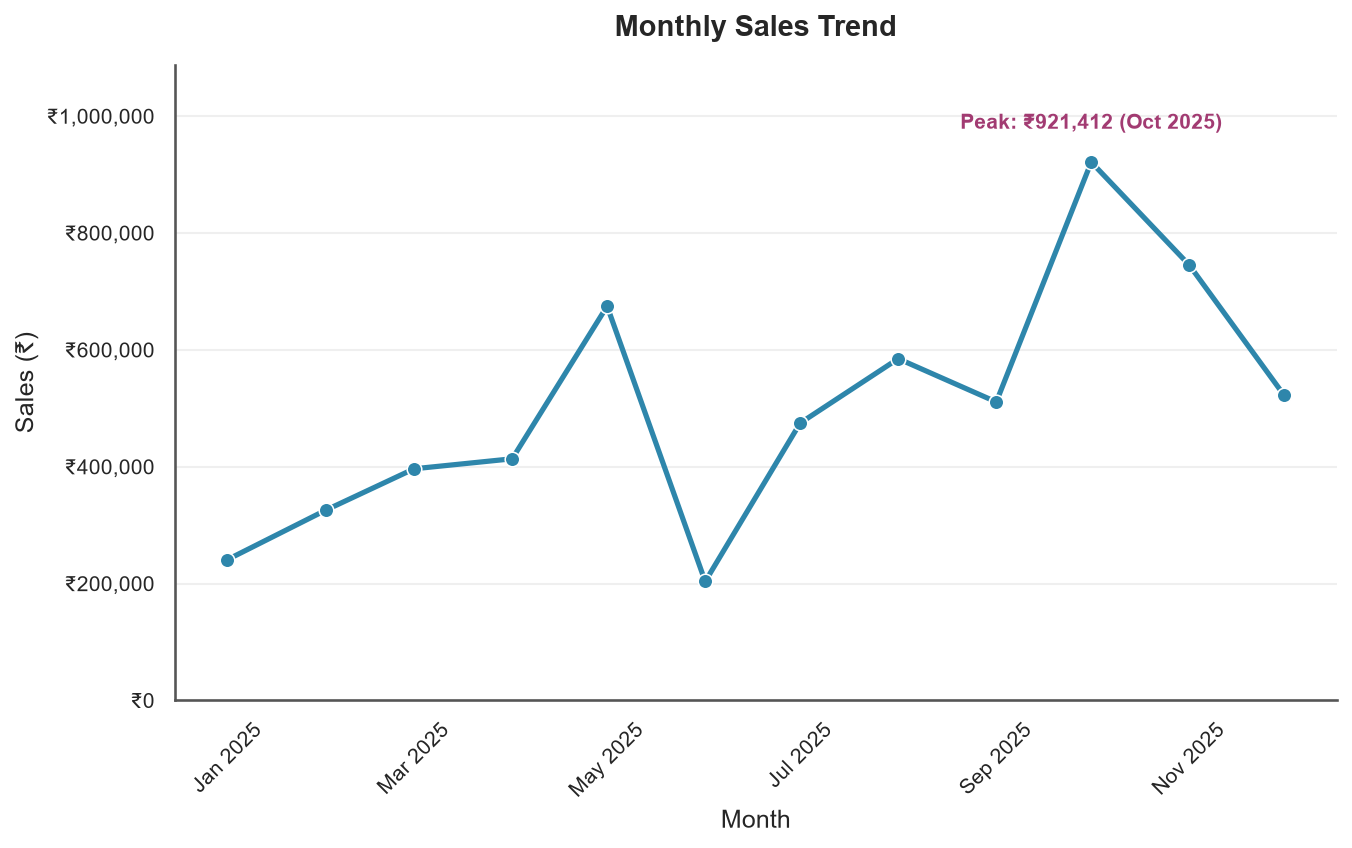

08_monthly_profit_trend.png


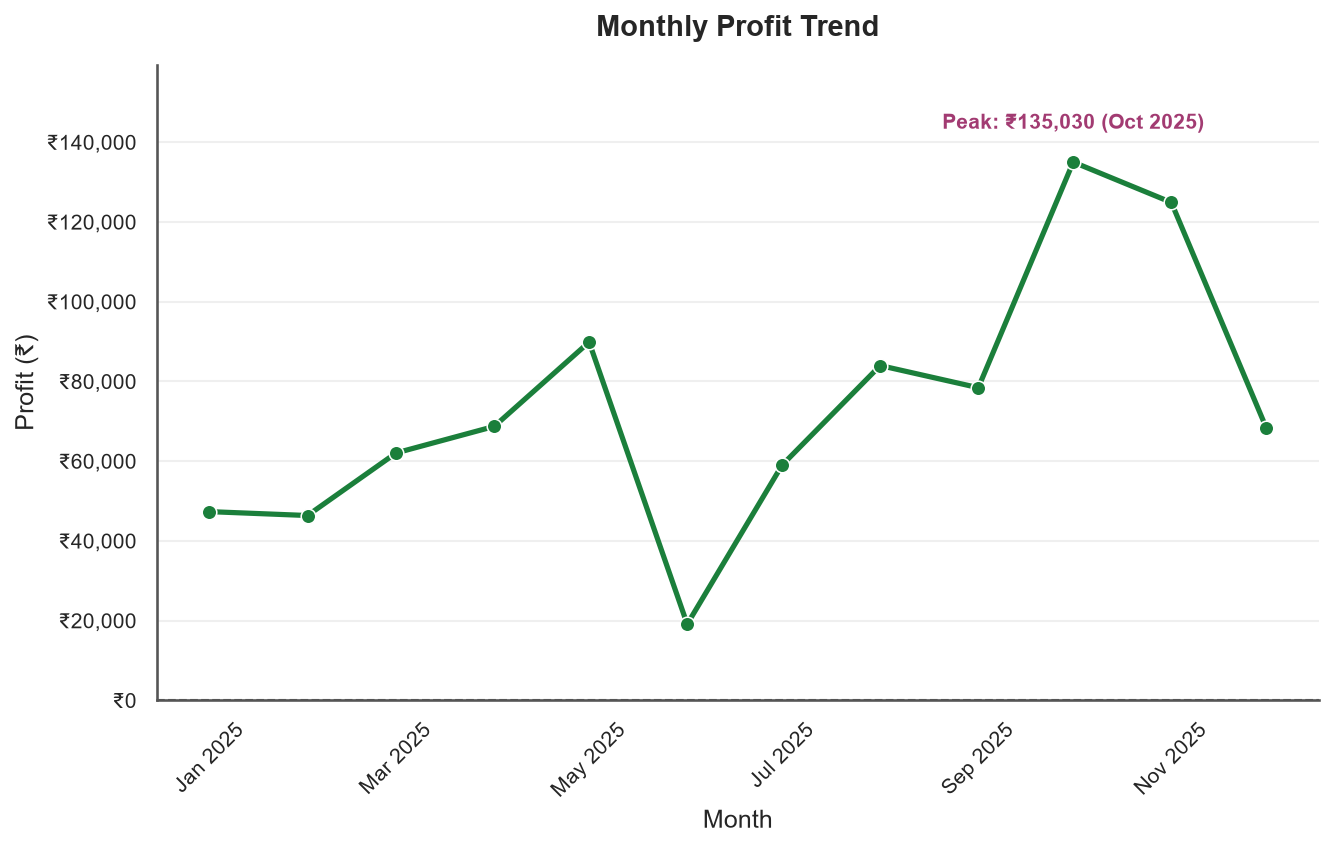

In [27]:
for path in chart_paths:
    print(path.name)
    display(Image(filename=str(path)))

## 16. Key Findings

In [28]:
findings = analysis.generate_key_findings(
    cleaned_df, kpis, category_perf, region_perf, top_sales, top_profit, monthly
)
print("KEY FINDINGS")
print("-" * 60)
for index, item in enumerate(findings, start=1):
    print(f"{index}. {item}")

KEY FINDINGS


------------------------------------------------------------
1. Total revenue was ₹6,013,456 across 616 orders and 1,437 units.
2. Total profit was ₹883,307 (overall margin 14.7%).
3. Average order value was ₹9,762.
4. Category 'Electronics' generated the highest sales (₹3,186,566, 53.0% of total).
5. Category 'Electronics' earned the highest profit (₹416,357).
6. Region 'North' led both sales (₹1,884,068) and profit (₹265,850).
7. 'Laptop' was the best-selling product (₹1,039,593 revenue, 20 units).
8. 'Tablet' was the most profitable product (₹135,582 profit).
9. Oct 2025 recorded the highest monthly sales (₹921,412); Jun 2025 was the lowest (₹203,530).
10. 105 orders (17.0%) were loss-making; 'Tea Pack' earned the lowest profit of all products (₹272).
11. Lowest-profit category: 'Grocery' (₹4,205); lowest-profit region: 'East' (₹149,893).


## 17. Business Recommendations

In [29]:
recommendations = analysis.generate_recommendations(
    cleaned_df, kpis, category_perf, region_perf, top_sales, monthly
)
print("BUSINESS RECOMMENDATIONS")
print("-" * 60)
for index, item in enumerate(recommendations, start=1):
    print(f"{index}. {item}")

BUSINESS RECOMMENDATIONS
------------------------------------------------------------
1. Double down on 'Electronics' - it leads both sales (53.0% of revenue) and profit (₹416,357); it is the strongest growth engine today.
2. Review pricing and discounts on low-margin category 'Grocery' (margin 3.7%) - heavy discounting is eroding profitability on otherwise popular items.
3. Strengthen the weakest region 'East' (profit ₹149,893) with local promotions, better distribution and a review of the regional cost-to-serve.
4. Maintain inventory for high-demand products: Rice Bag 5kg (125 units), Cotton Shirt (109 units), Detergent Powder (99 units), Cooking Oil 1L (99 units), Sports Shoes (93 units).
5. Plan promotions around the trend: sales peak in Oct 2025 (₹921,412) and dip in Jun 2025 (₹203,530) - run campaigns before the peak and targeted offers to lift the slow months.
6. Lowest-profit products need a cost and pricing review first: Tea Pack (₹272), Rice Bag 5kg (₹605), Cooking Oil 1L (₹7

## 18. Final Conclusion

The analysis covered the full workflow - data quality checks and cleaning,
KPI calculation, category/region/product/monthly analysis, visualisation and
insight generation - with every number computed directly from the dataset.

The generated artefacts are:

- `outputs/charts/` - 8 PNG charts
- `outputs/summary.csv` - KPI summary
- `outputs/sales_data_cleaned.csv` - cleaned dataset
- `outputs/reports/` - cleaning report, analysis report and aggregate tables

In [30]:
conclusion = (
    f"Across {kpis['Total Orders']:,} orders in 2025, the business generated "
    f"{analysis.format_inr(kpis['Total Sales'])} in revenue and "
    f"{analysis.format_inr(kpis['Total Profit'])} in profit "
    f"({analysis.format_pct(kpis['Profit Margin (%)'])} margin). "
    f"'{top_sales.iloc[0]['Product']}' was the best-selling product, "
    f"'{best_sales_cat['Category']}' was the strongest category and "
    f"'{best_profit_reg['Region']}' was the strongest region. "
    f"Sales peaked in {peak['Month_Label']} and dipped in {low['Month_Label']}. "
    "The recommendations above target the weakest segments identified by the data."
)
print(conclusion)

Across 616 orders in 2025, the business generated ₹6,013,456 in revenue and ₹883,307 in profit (14.7% margin). 'Laptop' was the best-selling product, 'Electronics' was the strongest category and 'North' was the strongest region. Sales peaked in Oct 2025 and dipped in Jun 2025. The recommendations above target the weakest segments identified by the data.
